[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_InputAwareBackdoor_Zhang2026.ipynb)

# Q-DIBA, an input-aware dynamic backdoor against quantum neural networks: Zhang et al. (2026) step by step

**Paper.** Junrui Zhang, Zemin Chen, Lusi Li, Mohammad Ghasemigol, Daniel Takabi and Rui Ning,
*Input-Aware Dynamic Backdoor Attack Against Quantum Neural Networks*, arXiv:2607.11843 (v2, July 2026),
Old Dominion University. <https://arxiv.org/abs/2607.11843>

**What this notebook does.** It re-implements the attack called **Q-DIBA** on MNIST digits, from scratch, in PennyLane and PyTorch:

1. an 8-qubit quantum neural network (QNN) that reads a 16x16 image through *amplitude encoding*;
2. a small classical **trigger generator** (a convolutional auto-encoder) that makes a *different* invisible trigger for every image;
3. the **three-mode training** (clean / backdoor / cross-trigger mini-batches) and the **ensemble density contrastive loss** on the quantum state *before* measurement;
4. the paper's metrics: clean accuracy (ACC/CA), backdoor accuracy (BA), attack success rate (ASR) and cross-trigger accuracy (CTA);
5. the paper's experiments in miniature: architectures (Table I), ablation of the contrastive loss (Table II), comparison with a classical fixed-patch backdoor (Table III), and three defences (visual inspection, spectral signature, fine-tuning; Fig. 5, Fig. 6, Table IV);
6. a classical baseline (random forest and RBF-SVM) on exactly the same 16x16 inputs, and an honest side-by-side comparison with the paper's numbers.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime and press *Runtime -> Run all*.
`FAST_MODE = True` (default in the configuration cell) is a class demo that finishes in about ten minutes; set it to `False` for the longer run
(documented in the configuration cell). Nothing needs a GPU, an IBM account or a Hugging Face token: MNIST is public. (If you ever swap in a *gated* dataset, put your own
token in Colab *Settings -> Secrets* as `HF_TOKEN`; the code below already looks for it there and in the environment variable `HF_TOKEN`.)

**What you get at the end.** A trained clean QNN and a backdoored QNN with the same circuit, drawings of the executed circuits, figures of the generated triggers, a table that puts every number of the paper next to
the number measured here with a verdict ("reproduced", "not reached", "exceeded", "cannot be checked"), and exercises.

> **Ethics.** This is a security-research reproduction. It attacks only a toy digit classifier trained inside this notebook. The point is to understand the threat so that defences against
> input-aware quantum backdoors can be designed and tested.

## The paper in one page

**Problem.** A QNN is a parameterised quantum circuit trained by a classical optimiser. A *backdoor* is a hidden behaviour implanted during training: the model works normally on clean inputs but outputs an
attacker-chosen class whenever a secret *trigger* is present. Earlier quantum backdoors (QTrojan, QDoor, Q-FGSM, QUAP, HarmQ) use **one fixed trigger** for all poisoned inputs, and that regularity is exactly what defences
(Neural Cleanse, spectral signatures, fine-tuning, visual inspection) look for.

**Idea.** *Input-aware dynamic backdoor*: a trigger generator `g_phi` produces a **different trigger for every input**, and the backdoor fires **only when an image carries its own trigger**. A trigger made from image *j*
and stamped on image *i* must do nothing. This turns the backdoor into an input-trigger *relation* rather than a pattern.

**Threat model.** The attacker controls the training procedure (a malicious training service) but cannot change the circuit that the user asked for; the delivered QNN has the same encoding, ansatz and measurement.
The attacker keeps the generator and uses it at inference time.

**Method (Section III).**
* Victim QNN `f_theta`: encoding `S(x)` (amplitude encoding of the 16x16 image on 8 qubits), ansatz `U(theta)`, Pauli readout `R`.
* Trigger injection (Eq. 4): `T(x, g) = x + eps * (2 g(x) - 1) * (max(x) - min(x))`, with `g` in [0, 1] from a sigmoid.
* Three-mode mini-batches (Eq. 5): each sample is *backdoor* (own trigger, label -> target) with probability `p_b = 0.1`, *clean* with `p_c = 0.8`, or *cross-trigger*
  (trigger of another sample `j != i`, true label kept) with probability `0.1`.
* Loss (Eq. 6-12): `L = L_cls + lambda_inv L_inv + lambda_ct L_ct`, where `L_cls` is a per-mode cross-entropy, `L_inv = E[(2g-1)^2]` keeps triggers small and
  `L_ct = max(0, 1 - d_HS(rho_B, rho_O))` pushes the *ensemble-averaged* density matrices of backdoor-mode and cross-mode states (taken after the ansatz, before measurement) at least one Hilbert-Schmidt unit apart.
* Training: 100 epochs, two Adam optimisers (QNN every iteration, generator every second iteration), batch 64, `eps = 0.02`, target class 0.

**Data and models.** MNIST (and Fashion-MNIST), 28x28 images average-pooled to 16x16, amplitude encoding on 8 qubits (TorchQuantum simulator). Three ansatz families, each with 10, 20 and 30 layers:
QNN1 = RX-RY-RZ + ring of CNOTs, QNN2 = RZ-RY-RZ + ring of CNOTs, QNN3 = alternating RZX and RXX gates; Pauli-Z readout (QNN1/2), Pauli-Y readout (QNN3).

**Claims we can test here (MNIST).** Table I: ACC/BA about 93-98 %, ASR above 95 %, CTA about 93 %. Table II: removing `L_ct` or its ensemble averaging degrades all three metrics. Table III: classical fixed-pattern backdoors
(BadNets) have ASR below 8 % on QNNs while Q-DIBA gets about 98 %. Fig. 6: spectral-signature outlier scores of Q-DIBA are close to a clean baseline. Table IV: after 20 fine-tuning epochs ASR stays above 91 %.

### What follows the paper and what had to be chosen

The paper does not publish code, the number of classes, learning rates, the generator layer sizes or how many images it trains on. Everything below that is not in the paper is a *choice* made here
and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Simulator | TorchQuantum | PennyLane circuit objects for drawing and checking, plus an exact PyTorch state-vector simulator for training (checked equal to the PennyLane QNode with `assert`) |
| Qubits / encoding | 8 qubits, 16x16 pooled image, amplitude encoding | same (`AmplitudeEmbedding`, 256 amplitudes, L2-normalised) |
| Ansatz | QNN1 (RX-RY-RZ + CNOT ring), QNN2 (RZ-RY-RZ + CNOT ring), QNN3 (RZX + RXX), 10/20/30 layers | same gate patterns; QNN3 as a ring of RZX gates followed by a ring of RXX gates (**CHOICE**: the exact wiring is not given); weights initialised uniformly in [0, 2 pi) (**CHOICE**) |
| Readout | Pauli-Z (QNN1/2) or Pauli-Y (QNN3) expectations | same, on qubits 0..3 |
| Classes | not stated | **CHOICE**: 4 classes (digits 0-3); 8 Pauli expectations cannot label 10 classes without extra readout, and a 4-class task is the TorchQuantum default |
| Logits | not stated | **CHOICE**: `LOGIT_SCALE x <P>` fed to the cross-entropy |
| Training set | not stated (100 epochs) | **CHOICE**: a class-balanced random subset of the MNIST training set (512 images FAST, 1200 images full) because simulating the circuit costs CPU time |
| Test set | not stated | **CHOICE**: class-balanced random subset of the official MNIST test set (never used for fitting or tuning) |
| Epochs | 100 | 25 in FAST, 60 in the full run (a CPU simulator budget) |
| Optimisers | two Adam; rates not given | **CHOICE**: Adam, lr 0.05 (QNN) and 0.02 (generator) |
| Generator | conv auto-encoder: 2 conv + linear latent + 2 transposed conv + sigmoid | same layout (**CHOICE**: 8 and 16 channels, latent size 32, last layer zero-initialised so that the sigmoid starts exactly at 0.5) |
| Trigger budget `eps` | 0.02 | **CHOICE (deviation)**: the main experiment uses `eps = 0.3`; with 0.02 the backdoor is not learned in our short CPU budget (shown in section 8b, where 0.02 is run too) |
| Mode probabilities, loss weights, batch, target | `p_c=0.8`, `p_b=0.1`, `lambda_inv=0.5`, others 1, batch 64, target 0 | same |
| Generator step | once every 2 iterations | same (gradients of the two skipped iterations accumulate) |
| Per-sample contrast ("w/o ensemble") | per-sample density matrices | **CHOICE**: pair the k-th backdoor-mode state with the k-th cross-mode state in the batch |
| ASR / CTA | ASR on non-target inputs with own trigger; CTA with another sample's trigger | same; CTA is computed on all test images, the "other sample" being a random different test image |
| Spectral-signature outlier score | defined only through Fig. 6 values | **CHOICE**: AUROC and a score ratio on the post-ansatz state (see section 11) |
| Fine-tuning defence | "a clean MNIST subset", epochs 5-20 | **CHOICE**: a held-out clean subset (disjoint from train and test), Adam lr 0.01 |
| Fashion-MNIST | second dataset | not run (MNIST only) |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships torch, numpy, pandas, scikit-learn, matplotlib.
# The cell does nothing when the packages are already importable (e.g. when running locally). A session restart may be required after installing.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _missing():
    try:
        import pennylane, torch, sklearn, pandas, matplotlib  # noqa: F401
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True
if IN_COLAB and _missing():
    !pip -q install "pennylane==0.45.1"

### Configuration
Every tunable constant is in this one cell. `FAST_MODE = True` is the class demo; `False` is the longer run (more images, 100 epochs as in the paper, three seeds, finer fine-tuning checkpoints).

In [2]:
# ----------------------------- CONFIGURATION (every tunable constant lives here) -----------------------------
SEED = 42
FAST_MODE = True              # True: ~10-minute class demo; False: the longer run documented below
DATA_DIR = "qdiba_data"           # MNIST is cached here (download or upload mnist.npz into this folder)
IBM_TOKEN = ""                    # unused: everything runs on an exact state-vector simulator (kept for the common template)

# --- the attack, exactly the numbers the paper gives (Section IV-A) ---------------------------------------------
N_QUBITS   = 8                    # paper: 8 qubits, 16x16 images, amplitude encoding (2^8 = 256 amplitudes)
EPS_PAPER  = 0.02                 # the paper's per-sample trigger budget epsilon (Eq. 4)
EPS        = 0.3                  # CHOICE: budget used by the main experiment (see section 8b: eps = 0.02 does not train in a short run)
P_B, P_C   = 0.1, 0.8             # backdoor / clean mode probabilities; cross-trigger mode gets the remaining 0.1
LAMBDA     = dict(b=1.0, c=1.0, o=1.0, inv=0.5, ct=1.0)   # lambda_b = lambda_c = lambda_o = 1, lambda_inv = 0.5, lambda_ct = 1
BATCH      = 64                   # mini-batch size
GEN_EVERY  = 2                    # generator updated once every 2 QNN iterations
TARGET     = 0                    # attacker target class

# --- things the paper does not state (marked "# CHOICE:" where they are used) -----------------------------------
N_CLASSES    = 4                  # CHOICE: digits 0-3, read out on the Pauli expectations of qubits 0-3
LOGIT_SCALE  = 8.0                # CHOICE: fixed multiplier turning <P> in [-1, 1] into logits for the cross-entropy
LR_QNN, LR_GEN = 0.05, 0.02       # CHOICE: Adam learning rates (paper: "two separate Adam optimizers", rates not given)

if FAST_MODE:
    TRAIN_N, TEST_N, FT_N = 512, 600, 192       # training images, test images, clean images for the fine-tuning defence
    EPOCHS            = 25                      # paper: 100
    TABLE1_GRID       = [(1, 10), (2, 10), (3, 10)]   # (architecture, layers) cells of Table I that get re-run
    SEEDS             = [42]
    FT_EPOCHS         = [5, 10]
    EPS_SWEEP         = [EPS_PAPER, EPS]
else:
    TRAIN_N, TEST_N, FT_N = 1200, 1000, 400
    EPOCHS            = 60                      # paper: 100 (see the note on run time in the top cell)
    TABLE1_GRID       = [(1, 10), (2, 10), (3, 10)]
    SEEDS             = [42, 43]
    FT_EPOCHS         = [5, 10, 15, 20]
    EPS_SWEEP         = [EPS_PAPER, 0.1, EPS]

In [3]:
import os, time, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_auc_score
warnings.filterwarnings("ignore")

# Hugging Face token (only needed if you replace MNIST by a gated dataset; resolved from the environment or Colab Secrets, never typed here)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits =", N_QUBITS, "| classes =", N_CLASSES, "| target =", TARGET)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = True | qubits = 8 | classes = 4 | target = 0


## 1. Data: MNIST digits, pooled to 16x16

MNIST is the standard handwritten-digit set (60 000 training and 10 000 test images, 28x28 grey pixels, labels 0-9). The paper average-pools each image to 16x16 = 256 numbers, which an 8-qubit state can hold as its
2^8 = 256 amplitudes (*amplitude encoding*). We download the public `mnist.npz` file (a mirror of the original data), cache it in `DATA_DIR`, keep digits 0-3 (**CHOICE**, see the table above),
draw a class-balanced random training subset, a class-balanced test subset, and a separate small clean subset that the *defender* uses for fine-tuning in section 10. All three come from different images.

In [4]:
import requests, io

def _download_mnist(path):
    urls = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
            "https://s3.amazonaws.com/img-datasets/mnist.npz"]
    for u in urls:
        try:
            r = requests.get(u, timeout=600); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return True
        except Exception as e:
            print("download failed:", u, type(e).__name__)
    return False

def _from_hf(path):
    # Fallback: Hugging Face mirror of MNIST (parquet with PNG bytes). Works with or without a token.
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for split, fn in [("train", "mnist/train-00000-of-00001.parquet"), ("test", "mnist/test-00000-of-00001.parquet")]:
        f = hf_hub_download("ylecun/mnist", fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)
        df = pd.read_parquet(f)
        out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out["y_" + split] = df["label"].to_numpy().astype(np.int64)
    np.savez_compressed(path, **out)

mnist_path = os.path.join(DATA_DIR, "mnist.npz")
if not os.path.exists(mnist_path):
    if not _download_mnist(mnist_path):
        _from_hf(mnist_path)
d = np.load(mnist_path)
x_tr_all, y_tr_all, x_te_all, y_te_all = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
print("full MNIST:", x_tr_all.shape, x_te_all.shape)

def pool16(x):                                   # (n,28,28) uint8 -> (n,1,16,16) float in [0,1], average pooling as in the paper
    t = torch.tensor(x, dtype=torch.float32)[:, None] / 255.0
    return F.adaptive_avg_pool2d(t, 16)

def balanced_subset(y, n, seed, exclude=None):
    # CHOICE: class-balanced random subset of digits 0..N_CLASSES-1
    r = np.random.default_rng(seed); per = n // N_CLASSES; idx = []
    for c in range(N_CLASSES):
        pool = np.where(y == c)[0]
        if exclude is not None: pool = np.setdiff1d(pool, exclude)
        idx.append(r.choice(pool, per, replace=False))
    idx = np.concatenate(idx); r.shuffle(idx); return idx

i_tr = balanced_subset(y_tr_all, TRAIN_N, SEED)
i_ft = balanced_subset(y_tr_all, FT_N, SEED + 1, exclude=i_tr)        # defender's clean fine-tuning set, disjoint from the training subset
i_te = balanced_subset(y_te_all, TEST_N, SEED + 2)
Xtr, ytr = pool16(x_tr_all[i_tr]), torch.tensor(y_tr_all[i_tr])
Xft, yft = pool16(x_tr_all[i_ft]), torch.tensor(y_tr_all[i_ft])
Xte, yte = pool16(x_te_all[i_te]), torch.tensor(y_te_all[i_te])
print("train", tuple(Xtr.shape), "| fine-tune", tuple(Xft.shape), "| test", tuple(Xte.shape))

full MNIST: (60000, 28, 28) (10000, 28, 28)


train (512, 1, 16, 16) | fine-tune (192, 1, 16, 16) | test (600, 1, 16, 16)


## Dataset Exploration and Visualisation

Before any quantum model: what are the real data? Below we print the shape, the feature names and the original label values with their counts, plot the real class distribution, show real digits, and project
the **real** training images to two dimensions with PCA (fitted on the training split only), coloured by the ground-truth digit. The QNN does not see raw pixels: amplitude encoding divides each 256-vector by its
length, so the second scatter plot shows those L2-normalised vectors (the actual quantum amplitudes). There is no angle encoding in this paper, so no [0, pi] rescaling applies.

Original MNIST: train (60000, 28, 28) test (10000, 28, 28) | pixel type uint8 range 0 - 255
Original label values (full training set): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Original label values (full test set)    : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}

Model input: 256 features per image (pooled pixel intensities in [0,1]); first names ['px_0_0', 'px_0_1', 'px_0_2'] ... last px_15_15
Digits kept for the 4-class task: [0, 1, 2, 3] | attacker target class: 0
train subset      {0: 128, 1: 128, 2: 128, 3: 128}
fine-tune subset  {0: 48, 1: 48, 2: 48, 3: 48}
test subset       {0: 150, 1: 150, 2: 150, 3: 150}


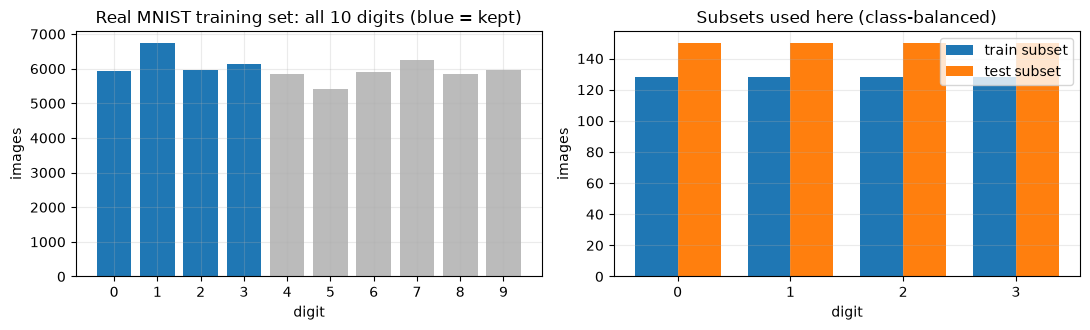

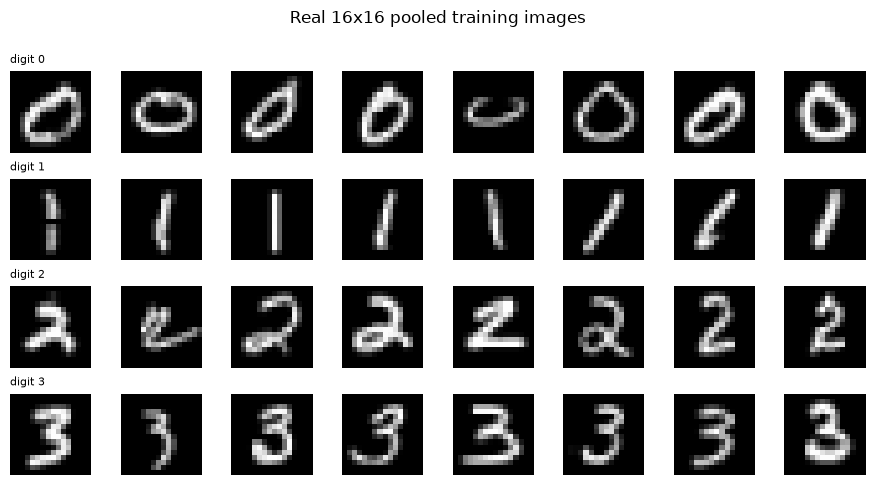

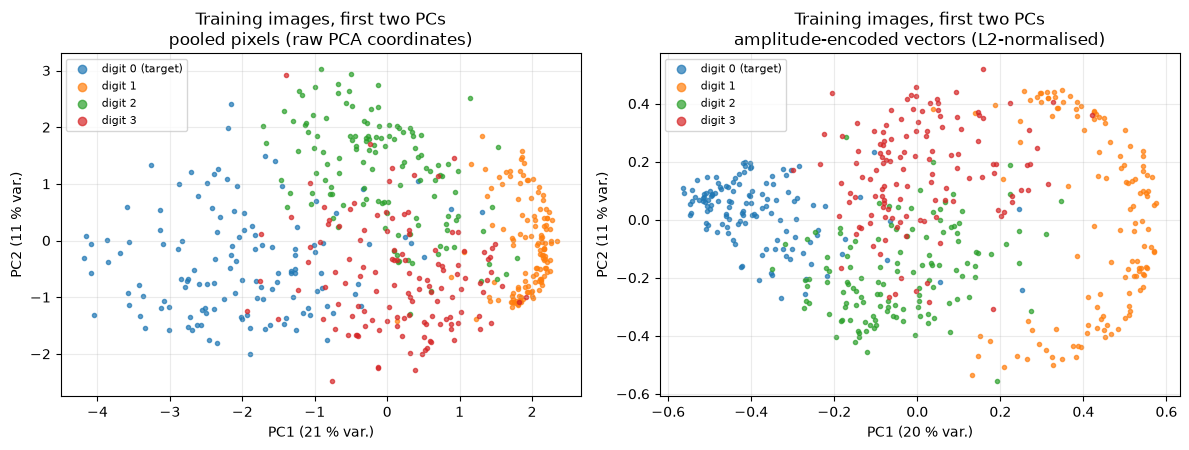

In [5]:
print("Original MNIST: train", x_tr_all.shape, "test", x_te_all.shape, "| pixel type", x_tr_all.dtype, "range", x_tr_all.min(), "-", x_tr_all.max())
print("Original label values (full training set):", dict(zip(*[a.tolist() for a in np.unique(y_tr_all, return_counts=True)])))
print("Original label values (full test set)    :", dict(zip(*[a.tolist() for a in np.unique(y_te_all, return_counts=True)])))
feat_names = [f"px_{r}_{c}" for r in range(16) for c in range(16)]
print(f"\nModel input: {len(feat_names)} features per image (pooled pixel intensities in [0,1]); first names {feat_names[:3]} ... last {feat_names[-1]}")
print("Digits kept for the 4-class task:", list(range(N_CLASSES)), "| attacker target class:", TARGET)
for nm, yy in [("train subset", ytr), ("fine-tune subset", yft), ("test subset", yte)]:
    print(f"{nm:17s}", dict(zip(*[a.tolist() for a in np.unique(yy.numpy(), return_counts=True)])))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cnt_all = np.bincount(y_tr_all, minlength=10)
ax[0].bar(range(10), cnt_all, color=["#1f77b4" if k < N_CLASSES else "#bbbbbb" for k in range(10)])
ax[0].set(title="Real MNIST training set: all 10 digits (blue = kept)", xlabel="digit", ylabel="images"); ax[0].set_xticks(range(10))
cnt_tr = np.bincount(ytr.numpy(), minlength=N_CLASSES); cnt_te = np.bincount(yte.numpy(), minlength=N_CLASSES)
w = 0.38
ax[1].bar(np.arange(N_CLASSES) - w / 2, cnt_tr, w, label="train subset"); ax[1].bar(np.arange(N_CLASSES) + w / 2, cnt_te, w, label="test subset")
ax[1].set(title="Subsets used here (class-balanced)", xlabel="digit", ylabel="images"); ax[1].set_xticks(range(N_CLASSES)); ax[1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(N_CLASSES, 8, figsize=(9, 1.2 * N_CLASSES))
for c in range(N_CLASSES):
    ii = np.where(ytr.numpy() == c)[0][:8]
    for k, i in enumerate(ii):
        ax[c, k].imshow(Xtr[i, 0], cmap="gray", vmin=0, vmax=1); ax[c, k].axis("off")
    ax[c, 0].set_title(f"digit {c}", fontsize=8, loc="left")
fig.suptitle("Real 16x16 pooled training images", y=1.0); plt.tight_layout(); plt.show()

# 2-D projections of the REAL training images, coloured by ground-truth digit; PCA fitted on the training split only
A_tr = Xtr.flatten(1).numpy(); A_te = Xte.flatten(1).numpy()
amp = lambda M: M / np.linalg.norm(M, axis=1, keepdims=True)
cols = plt.cm.tab10(np.arange(10))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for k, (nm, ftr, fte) in enumerate([("pooled pixels (raw PCA coordinates)", A_tr, A_te), ("amplitude-encoded vectors (L2-normalised)", amp(A_tr), amp(A_te))]):
    pca_v = PCA(n_components=2, random_state=SEED).fit(ftr)
    Z = pca_v.transform(ftr)
    for c in range(N_CLASSES):
        m = ytr.numpy() == c
        ax[k].scatter(Z[m, 0], Z[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {c}" + (" (target)" if c == TARGET else ""))
    ax[k].set(title=f"Training images, first two PCs\n{nm}", xlabel=f"PC1 ({100 * pca_v.explained_variance_ratio_[0]:.0f} % var.)", ylabel=f"PC2 ({100 * pca_v.explained_variance_ratio_[1]:.0f} % var.)")
    ax[k].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Classical baseline on the identical inputs

Before trusting any quantum number we need a yardstick: a random forest and an RBF support-vector machine trained on exactly the same 256 pooled pixels (L2-normalised like the amplitudes) and the same train/test
images. These are *clean* models; they say how hard the 4-class task is, not how a backdoor behaves.

In [6]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(amp(A_tr), ytr.numpy())
svm = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(amp(A_tr), ytr.numpy())
base = {"RandomForest": 100 * (rf.predict(amp(A_te)) == yte.numpy()).mean(), "SVC (rbf)": 100 * (svm.predict(amp(A_te)) == yte.numpy()).mean()}
print({k: round(v, 2) for k, v in base.items()}, f"| {time.time() - t0:.1f} s")

{'RandomForest': np.float64(98.17), 'SVC (rbf)': np.float64(98.33)} | 2.2 s


## 3. The building blocks

**Simulator.** The paper simulates its circuits with TorchQuantum. Here the same circuits exist twice: as PennyLane `QNode`s (used for the circuit drawings further below and for correctness checks) and as a compact exact
PyTorch state-vector simulator (used for training, because it is faster on a CPU and gives us the post-ansatz state `|psi>` that the contrastive loss needs). The two are checked to agree to 1e-4 further below.

**Trigger generator `g_phi`.** A convolutional auto-encoder (two strided convolutions, a linear latent code, two transposed convolutions, a sigmoid) maps a 16x16 image to a 16x16 map in [0, 1].
Equation (4) turns it into a trigger of at most `eps` times the image's own intensity range: `x_triggered = x + eps (2 g - 1) (max x - min x)`. It is a **classical** network, not a quantum circuit.

**Ensemble density contrastive loss.** For a set of pure states, the averaged density matrix is `rho = mean |psi_i><psi_i|`. The Hilbert-Schmidt distance between two such averages can be computed without ever forming a
256x256 matrix: `||rho_B - rho_O||^2 = tr(rho_B^2) + tr(rho_O^2) - 2 tr(rho_B rho_O)` with `tr(rho_A rho_B) = mean_ij |<a_i|b_j>|^2`. A cell below checks this against the explicit matrices.

In [7]:
# ---- fast exact state-vector simulator (torch, autograd) ------------------------------
NQ = 8
DIM = 2 ** NQ

def _bits(j, q):                       # value of qubit q (wire 0 = most significant bit) in basis state j
    return (j >> (NQ - 1 - q)) & 1

def _pauli_string(ops):
    """ops: dict {wire: 'X'|'Y'|'Z'} -> (perm, phase) with  (P psi)[j'] = phase[j'] * psi[perm[j']]."""
    perm = np.arange(DIM); phase = np.ones(DIM, dtype=np.complex128)
    for j in range(DIM):                # P|j> = ph(j) |j xor mask>
        k, ph = j, 1.0 + 0j
        for q, p in ops.items():
            b = _bits(j, q)
            if p == "X":
                k ^= 1 << (NQ - 1 - q)
            elif p == "Y":
                k ^= 1 << (NQ - 1 - q); ph *= (1j if b == 0 else -1j)
            elif p == "Z":
                ph *= (1 if b == 0 else -1)
        perm[k] = j; phase[k] = ph      # output index k receives phase * psi[j]
    return torch.tensor(perm, dtype=torch.long), torch.tensor(phase, dtype=torch.complex64)

_PS_CACHE = {}
def pauli_apply(psi, ops):
    key = tuple(sorted(ops.items()))
    if key not in _PS_CACHE:
        _PS_CACHE[key] = _pauli_string(ops)
    perm, phase = _PS_CACHE[key]
    return phase * torch.index_select(psi, 1, perm)

def _cnot_ring_perm():
    inv = np.arange(DIM)
    for j in range(DIM):
        bits = [_bits(j, q) for q in range(NQ)]
        for q in range(NQ):             # CNOT(q, q+1 mod n) applied in order q = 0..n-1 (as in the circuit)
            if bits[q]:
                bits[(q + 1) % NQ] ^= 1
        k = 0
        for q in range(NQ):
            k = (k << 1) | bits[q]
        inv[k] = j
    return torch.tensor(inv, dtype=torch.long)

CNOT_RING_SRC = _cnot_ring_perm()       # new_psi[k] = psi[CNOT_RING_SRC[k]]
CNOT_RING_MAT =torch.zeros(DIM, DIM, dtype=torch.complex64); CNOT_RING_MAT[torch.arange(DIM), CNOT_RING_SRC] = 1   # same permutation as a matrix

def _rot(kind, t):
    """Batched single-qubit rotations: t has any shape S, result S + (2, 2) complex64."""
    c, s = torch.cos(t / 2), torch.sin(t / 2); z = torch.zeros_like(t)
    if kind == "x":
        m = torch.stack([c + 0j, -1j * s, -1j * s, c + 0j], -1)
    elif kind == "y":
        m = torch.stack([c + 0j, -s + 0j, s + 0j, c + 0j], -1)
    else:
        e = torch.exp(-0.5j * t); m = torch.stack([e, z + 0j, z + 0j, e.conj()], -1)
    return m.reshape(*t.shape, 2, 2)

def _kron_tree(m):
    """m: (L, 8, 2, 2) -> (L, 256, 256): Kronecker product over the qubit axis (wire 0 = most significant)."""
    while m.shape[1] > 1:
        a, b = m[:, 0::2], m[:, 1::2]
        m = torch.einsum("lqij,lqkm->lqikjm", a, b).reshape(m.shape[0], m.shape[1] // 2, a.shape[2] * b.shape[2], a.shape[3] * b.shape[3])
    return m[:, 0]

def layer_unitaries(w, arch):
    """Single-qubit-rotation part of every layer of QNN1 / QNN2, built for all layers at once."""
    if arch == 1:
        us = _rot("z", w[..., 2]) @ _rot("y", w[..., 1]) @ _rot("x", w[..., 0])
    else:
        us = _rot("z", w[..., 2]) @ _rot("y", w[..., 1]) @ _rot("z", w[..., 0])
    return _kron_tree(us)

def fast_qnn_state(x, w, arch):
    """x: (B,256) real, w: (L,8,3). Returns the post-ansatz state (B,256) complex64.
    Amplitude encoding (L2-normalised), then L layers of the chosen ansatz (see make_pl_qnn for the PennyLane twin)."""
    psi = (x / x.norm(dim=1, keepdim=True).clamp_min(1e-8)).to(torch.complex64)
    L = w.shape[0]
    Us = layer_unitaries(w, arch).unbind(0) if arch in (1, 2) else None  # unbind: cheap backward
    for l in range(L):
        if arch in (1, 2):
            psi = torch.index_select(psi @ Us[l].T, 1, CNOT_RING_SRC)
        else:                            # QNN3: ring of RZX gates, then ring of RXX gates
            for q in range(NQ):
                t = w[l, q, 0]
                psi = torch.cos(t / 2) * psi - 1j * torch.sin(t / 2) * pauli_apply(psi, {q: "Z", (q + 1) % NQ: "X"})
            for q in range(NQ):
                t = w[l, q, 1]
                psi = torch.cos(t / 2) * psi - 1j * torch.sin(t / 2) * pauli_apply(psi, {q: "X", (q + 1) % NQ: "X"})
    return psi
def expvals(psi, meas, ncls):
    out = []
    for i in range(ncls):
        Ppsi = pauli_apply(psi, {i: meas})
        out.append((psi.conj() * Ppsi).sum(1).real)
    return torch.stack(out, 1)

ARCH_MEAS = {1: "Z", 2: "Z", 3: "Y"}

def init_weights(arch, L, seed):
    g = torch.Generator().manual_seed(seed)
    n_par = 2 if arch == 3 else 3                    # QNN3 has two rotation angles per qubit and layer (RZX, RXX)
    return (torch.rand(L, NQ, n_par, generator=g) * 2 * np.pi).requires_grad_(True)   # CHOICE: uniform [0, 2pi)

# ---- the same QNN as a PennyLane QNode (used for the drawings and an equivalence check) ----
def make_pl_qnn(arch, L, ncls=N_CLASSES):
    dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        qml.AmplitudeEmbedding(x, wires=range(NQ), normalize=True)
        for l in range(L):
            if arch == 1:
                for q in range(NQ):
                    qml.RX(w[l, q, 0], wires=q); qml.RY(w[l, q, 1], wires=q); qml.RZ(w[l, q, 2], wires=q)
                for q in range(NQ):
                    qml.CNOT(wires=[q, (q + 1) % NQ])
            elif arch == 2:
                for q in range(NQ):
                    qml.RZ(w[l, q, 0], wires=q); qml.RY(w[l, q, 1], wires=q); qml.RZ(w[l, q, 2], wires=q)
                for q in range(NQ):
                    qml.CNOT(wires=[q, (q + 1) % NQ])
            else:
                for q in range(NQ):
                    qml.PauliRot(w[l, q, 0], "ZX", wires=[q, (q + 1) % NQ])
                for q in range(NQ):
                    qml.IsingXX(w[l, q, 1], wires=[q, (q + 1) % NQ])
        P = qml.PauliZ if ARCH_MEAS[arch] == "Z" else qml.PauliY
        return [qml.expval(P(i)) for i in range(ncls)]
    return circuit

# ---- trigger generator g_phi : compact convolutional auto-encoder (16x16 -> latent -> 16x16) ----
class TriggerGenerator(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 8, 3, 2, 1), nn.ReLU(), nn.Conv2d(8, 16, 3, 2, 1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(16 * 4 * 4, latent))
        self.dec_fc = nn.Linear(latent, 16 * 4 * 4)
        self.dec = nn.Sequential(nn.ConvTranspose2d(16, 8, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(8, 1, 4, 2, 1))
        nn.init.zeros_(self.dec[-1].weight); nn.init.zeros_(self.dec[-1].bias)    # CHOICE: sigmoid starts at exactly 0.5
    def forward(self, x):                  # x: (B,1,16,16) -> g in [0,1]
        h = F.relu(self.dec_fc(self.enc(x))).view(-1, 16, 4, 4)
        return torch.sigmoid(self.dec(h))

def inject(x, g, eps):                     # Eq. (4)
    delta = (x.amax(dim=(1, 2, 3), keepdim=True) - x.amin(dim=(1, 2, 3), keepdim=True))
    return x + eps * (2 * g - 1) * delta

# ---- losses ------------------------------------------------------------------------------
def hs_dist(psiA, psiB):
    """Hilbert-Schmidt distance between the ensemble-averaged pure-state density matrices (Eqs. 10-11),
    computed from overlaps:  ||rA - rB||^2 = tr rA^2 + tr rB^2 - 2 tr rA rB,  tr rA rB = mean_ij |<a_i|b_j>|^2."""
    def tr(P, Q): return (torch.abs(P.conj() @ Q.T) ** 2).mean()
    d2 = tr(psiA, psiA) + tr(psiB, psiB) - 2 * tr(psiA, psiB)
    return torch.sqrt(d2.clamp_min(0) + 1e-8)

def hs_dist_explicit(psiA, psiB):          # reference implementation with explicit 256x256 matrices
    rA = torch.einsum("bi,bj->ij", psiA, psiA.conj()) / len(psiA)
    rB = torch.einsum("bi,bj->ij", psiB, psiB.conj()) / len(psiB)
    D = rA - rB
    return torch.sqrt((D.conj().T @ D).diagonal().sum().real)

def contrastive_loss(psi_b, psi_o, ensemble=True):
    if len(psi_b) == 0 or len(psi_o) == 0:
        return torch.zeros(())
    if ensemble:
        return torch.clamp(1 - hs_dist(psi_b, psi_o), min=0)
    n = min(len(psi_b), len(psi_o))        # per-sample variant ("w/o ensemble"): pair single states
    d = torch.stack([hs_dist(psi_b[i:i + 1], psi_o[i:i + 1]) for i in range(n)])
    return torch.clamp(1 - d, min=0).mean()

In [8]:
class QNN:
    """Victim QNN f_theta: amplitude encoding -> ansatz -> Pauli readout (first N_CLASSES qubits)."""
    def __init__(self, arch, L, seed):
        self.arch, self.L = arch, L
        self.w = init_weights(arch, L, seed)
    def forward(self, x16):                 # x16: (B,1,16,16)
        psi = fast_qnn_state(x16.flatten(1), self.w, self.arch)
        logits = LOGIT_SCALE * expvals(psi, ARCH_MEAS[self.arch], N_CLASSES)
        return psi, logits
    @torch.no_grad()
    def predict(self, x16, bs=500):
        return torch.cat([self.forward(x16[i:i + bs])[1].argmax(1) for i in range(0, len(x16), bs)])

def train_qnn(arch, L, X, y, epochs, seed, mode="clean", G=None, eps=EPS, lam=None, ensemble=True,
              use_ct=True, patch_fn=None, log=None, cb=None, cb_every=0):
    """mode='clean'   : benign training (cross-entropy on clean samples only)
       mode='qdiba'   : joint training of QNN and generator with the three-mode batches (Eqs. 5-12)
       mode='badnets' : fixed-patch data poisoning with the same poison rate p_b (classical baseline attack)"""
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    lam = lam or LAMBDA
    qnn = QNN(arch, L, seed)
    optQ = torch.optim.Adam([qnn.w], lr=LR_QNN)
    if mode == "qdiba":
        G = TriggerGenerator(); optG = torch.optim.Adam(G.parameters(), lr=LR_GEN)
    n = len(X); hist = []
    it = 0
    for ep in range(epochs):
        idx = rng.permutation(n); tot = np.zeros(4); nb = 0
        for s in range(0, n - BATCH + 1, BATCH):
            b = idx[s:s + BATCH]; xb, yb = X[b], y[b]
            if mode == "clean":
                _, lg = qnn.forward(xb); loss = F.cross_entropy(lg, yb); parts = [loss.item(), 0, 0, 0]
            elif mode == "badnets":
                u = rng.random(BATCH); pois = torch.tensor(u < P_B)
                xin = xb.clone(); yin = yb.clone()
                xin[pois] = patch_fn(xb[pois]); yin[pois] = TARGET
                _, lg = qnn.forward(xin); loss = F.cross_entropy(lg, yin); parts = [loss.item(), 0, 0, 0]
            else:
                u = rng.random(BATCH)
                mB = torch.tensor(u < P_B); mC = torch.tensor((u >= P_B) & (u < P_B + P_C)); mO = ~(mB | mC)
                g = G(xb)
                j = torch.tensor((np.arange(BATCH) + rng.integers(1, BATCH, BATCH)) % BATCH)   # j != i
                x_self = inject(xb, g, eps); x_cross = inject(xb, g[j], eps)
                xin = torch.where(mB.view(-1, 1, 1, 1), x_self, torch.where(mC.view(-1, 1, 1, 1), xb, x_cross))
                yin = torch.where(mB, torch.full_like(yb, TARGET), yb)
                psi, lg = qnn.forward(xin)
                ce = lambda m: F.cross_entropy(lg[m], yin[m]) if m.any() else torch.zeros(())
                Lcls = lam["b"] * ce(mB) + lam["c"] * ce(mC) + lam["o"] * ce(mO)
                Linv = ((2 * g - 1) ** 2).mean()
                Lct = contrastive_loss(psi[mB], psi[mO], ensemble) if use_ct else torch.zeros(())
                loss = Lcls + lam["inv"] * Linv + lam["ct"] * Lct
                parts = [Lcls.item(), Linv.item(), Lct.item(), 0]
            optQ.zero_grad()
            loss.backward()
            optQ.step()
            if mode == "qdiba":
                if it % GEN_EVERY == GEN_EVERY - 1:      # generator updated once every GEN_EVERY iterations
                    optG.step(); optG.zero_grad()
            tot += np.array(parts); nb += 1; it += 1
        hist.append(tot / max(nb, 1))
        if cb and cb_every and (ep + 1) % cb_every == 0:
            cb(ep + 1, qnn, G)
        if log and ((ep + 1) % log == 0 or ep == 0):
            print(f"    epoch {ep + 1:3d}/{epochs}  loss parts {np.round(hist[-1][:3], 3)}", flush=True)
    return qnn, G, np.array(hist)

@torch.no_grad()
def evaluate(qnn, G, X, y, eps=EPS, patch_fn=None, seed=0):
    """ACC (clean), ASR (non-target samples + own trigger -> target), CTA (trigger of another sample, true label kept)."""
    rng = np.random.default_rng(seed)
    acc = (qnn.predict(X) == y).float().mean().item()
    nt = y != TARGET
    if patch_fn is None and G is None:
        return dict(ACC=100 * acc, ASR=float("nan"), CTA=float("nan"))
    if patch_fn is not None:
        xs = patch_fn(X); asr = (qnn.predict(xs[nt]) == TARGET).float().mean().item(); cta = float("nan")
    else:
        g = G(X); xs = inject(X, g, eps)
        asr = (qnn.predict(xs[nt]) == TARGET).float().mean().item()
        j = torch.tensor((np.arange(len(X)) + rng.integers(1, len(X), len(X))) % len(X))
        xc = inject(X, g[j], eps)
        cta = (qnn.predict(xc) == y).float().mean().item()
    return dict(ACC=100 * acc, ASR=100 * asr, CTA=100 * cta)

In [9]:
# --- sanity checks of the building blocks -----------------------------------------------------------------
# (1) the overlap formula for the Hilbert-Schmidt distance equals the explicit 256x256 density-matrix computation
a = fast_qnn_state(Xtr[:7].flatten(1), init_weights(1, 3, 0).detach(), 1); b = fast_qnn_state(Xtr[7:12].flatten(1), init_weights(1, 3, 0).detach(), 1)
d_fast, d_ref = hs_dist(a, b).item(), hs_dist_explicit(a, b).item()
assert abs(d_fast - d_ref) < 1e-3, (d_fast, d_ref)
print(f"d_HS by overlaps = {d_fast:.5f} | by explicit density matrices = {d_ref:.5f}  -> equal")
# (2) the trigger is invisible at initialisation (sigmoid = 0.5 -> 2g-1 = 0) and bounded by eps * range afterwards
G0 = TriggerGenerator(); x0 = Xtr[:4]
print("max |trigger| at initialisation:", float((inject(x0, G0(x0), EPS) - x0).abs().max()), "| budget eps*range =", float(EPS * (x0.amax() - x0.amin())))
print("generator parameters:", sum(p.numel() for p in G0.parameters()))

d_HS by overlaps = 0.61833 | by explicit density matrices = 0.61833  -> equal


max |trigger| at initialisation: 0.0 | budget eps*range = 0.29823532700538635
generator parameters: 20105


## 4. Training the clean QNN and the backdoored QNN

Two victims with the **same circuit** (QNN1, 10 layers, 240 trainable angles):

* **clean**: ordinary cross-entropy training (this is the paper's CA, the accuracy a benign model reaches);
* **Q-DIBA**: joint training of the QNN and the trigger generator with the three-mode mini-batches and the loss of Eq. (6).

After each block of epochs we evaluate the four metrics on the held-out test images, so the curves show how the backdoor is *learned over time*. (Evaluation uses the test subset only to **report**; no parameter or
hyper-parameter is chosen from it.)

In [10]:
ARCH, LAYERS = 1, 10
curve = []
def log_eval(ep, q, G):
    m = evaluate(q, G, Xte, yte, seed=SEED); curve.append(dict(epoch=ep, **m))
    print(f"      [eval] epoch {ep:3d}  ACC {m['ACC']:.1f}  ASR {m['ASR']:.1f}  CTA {m['CTA']:.1f}", flush=True)

def run_attack(arch, L, seed, mode="qdiba", epochs=None, **kw):
    t0 = time.time()
    q, G, hist = train_qnn(arch, L, Xtr, ytr, epochs or EPOCHS, seed, mode, **kw)
    m = evaluate(q, G, Xte, yte, eps=kw.get("eps", EPS), patch_fn=kw.get("patch_fn"), seed=seed)
    m["time_s"] = time.time() - t0
    return q, G, hist, m

runs = {}                                                    # (arch, L, seed, mode) -> (qnn, generator, history, metrics)
for seed in SEEDS:
    print(f"seed {seed}: clean QNN{ARCH}-{LAYERS}"); runs[(ARCH, LAYERS, seed, "clean")] = run_attack(ARCH, LAYERS, seed, "clean")
    print(f"seed {seed}: Q-DIBA QNN{ARCH}-{LAYERS}")
    runs[(ARCH, LAYERS, seed, "qdiba")] = run_attack(ARCH, LAYERS, seed, "qdiba", log=max(1, EPOCHS // 4),
                                                     cb=log_eval if seed == SEEDS[0] else None, cb_every=max(1, EPOCHS // 5))
clean_q, _, clean_hist, clean_m = runs[(ARCH, LAYERS, SEEDS[0], "clean")]
bd_q, bd_G, bd_hist, bd_m = runs[(ARCH, LAYERS, SEEDS[0], "qdiba")]
print("\nclean   :", {k: round(v, 2) for k, v in clean_m.items()})
print("Q-DIBA  :", {k: round(v, 2) for k, v in bd_m.items()})

seed 42: clean QNN1-10


seed 42: Q-DIBA QNN1-10


    epoch   1/25  loss parts [3.561 0.    0.468]


      [eval] epoch   5  ACC 87.7  ASR 53.6  CTA 58.0


    epoch   6/25  loss parts [2.208 0.109 0.444]


...

    epoch  18/25  loss parts [1.814 0.104 0.522]


      [eval] epoch  20  ACC 96.0  ASR 72.7  CTA 60.0


    epoch  24/25  loss parts [1.723 0.12  0.503]


      [eval] epoch  25  ACC 95.3  ASR 85.1  CTA 55.7



clean   : {'ACC': 96.33, 'ASR': nan, 'CTA': nan, 'time_s': 227.67}
Q-DIBA  : {'ACC': 95.33, 'ASR': 85.11, 'CTA': 55.67, 'time_s': 126.51}


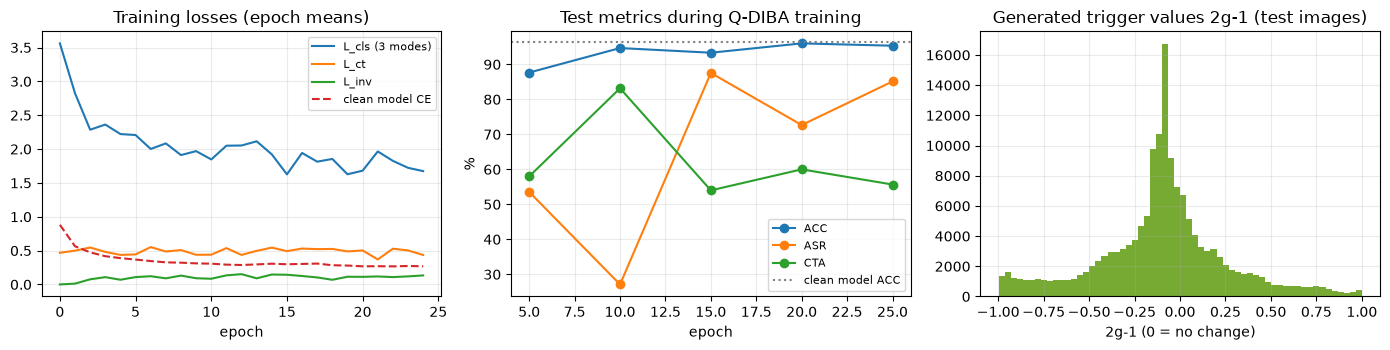

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(bd_hist[:, 0], label="L_cls (3 modes)"); ax[0].plot(bd_hist[:, 2], label="L_ct"); ax[0].plot(bd_hist[:, 1], label="L_inv")
ax[0].plot(clean_hist[:, 0], "--", label="clean model CE"); ax[0].set(title="Training losses (epoch means)", xlabel="epoch"); ax[0].legend(fontsize=8)
cv = pd.DataFrame(curve)
for k in ["ACC", "ASR", "CTA"]: ax[1].plot(cv["epoch"], cv[k], marker="o", label=k)
ax[1].axhline(clean_m["ACC"], color="gray", ls=":", label="clean model ACC"); ax[1].set(title="Test metrics during Q-DIBA training", xlabel="epoch", ylabel="%"); ax[1].legend(fontsize=8)
g_all = bd_G(Xte).detach(); ax[2].hist((2 * g_all - 1).flatten().numpy(), bins=60, color="#7a3"); ax[2].set(title="Generated trigger values 2g-1 (test images)", xlabel="2g-1 (0 = no change)")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The victim QNN has three stages (the paper's Fig. 1): an **encoding** circuit (amplitude encoding of the 256 pooled pixels on 8 qubits), a **parameterised circuit** (10 layers of the ansatz) and a **measurement**
(Pauli expectation values of qubits 0-3, which become the four class logits). The drawings below are produced by `qml.draw_mpl` on the very `QNode` that is compared, to 1e-4, with the training simulator, so they show the
circuit that is actually executed. The threat model says the attacker **cannot change the circuit**, so the backdoored QNN is drawn with the *same* gates and only different angle values.

* The gate lists of QNN1 and QNN2 are fixed by the paper (RX-RY-RZ or RZ-RY-RZ on every qubit, then a ring of CNOTs: control `q`, target `q+1 mod 8`, applied in order `q = 0..7`). **CHOICE:** the CNOT ring order and the QNN3 wiring
  (a ring of RZX gates followed by a ring of RXX gates on neighbouring qubits, `q` and `q+1 mod 8`) are not specified in the paper.
* The `AmplitudeEmbedding` box prepares the (normalised) image as the initial state. In the drawing it is shown with the numbers of one real test image.
* The **trigger generator is a classical neural network**, so it has no circuit; it is summarised in text below.

In [12]:
# (a) equivalence: the training simulator reproduces the PennyLane QNode (clean and backdoored weights, all three architectures)
def check_equiv(arch, L, w, X):
    circ = make_pl_qnn(arch, L)
    ref = torch.stack([torch.stack(circ(x, w.detach())) for x in X.flatten(1)]).float()
    mine = expvals(fast_qnn_state(X.flatten(1), w.detach(), arch), ARCH_MEAS[arch], N_CLASSES)
    return (ref - mine).abs().max().item()
Xchk = Xte[:4]
errs = {"QNN1-10 clean weights": check_equiv(1, LAYERS, clean_q.w, Xchk), "QNN1-10 backdoored weights": check_equiv(1, LAYERS, bd_q.w, Xchk),
        "QNN2-10 random weights": check_equiv(2, LAYERS, init_weights(2, LAYERS, 1), Xchk), "QNN3-10 random weights": check_equiv(3, LAYERS, init_weights(3, LAYERS, 1), Xchk)}
for k, v in errs.items(): print(f"max |PennyLane - simulator| on 4 real images, {k}: {v:.2e}")
assert max(errs.values()) < 1e-4, errs

max |PennyLane - simulator| on 4 real images, QNN1-10 clean weights: 4.77e-07
max |PennyLane - simulator| on 4 real images, QNN1-10 backdoored weights: 3.58e-07
max |PennyLane - simulator| on 4 real images, QNN2-10 random weights: 2.98e-07
max |PennyLane - simulator| on 4 real images, QNN3-10 random weights: 3.87e-07


Clean QNN1-10 (trained, angles in rad): qubits = 8, circuit depth = 111, gates = 321, trainable angles = 240, readout = Pauli-Z on qubits 0..3


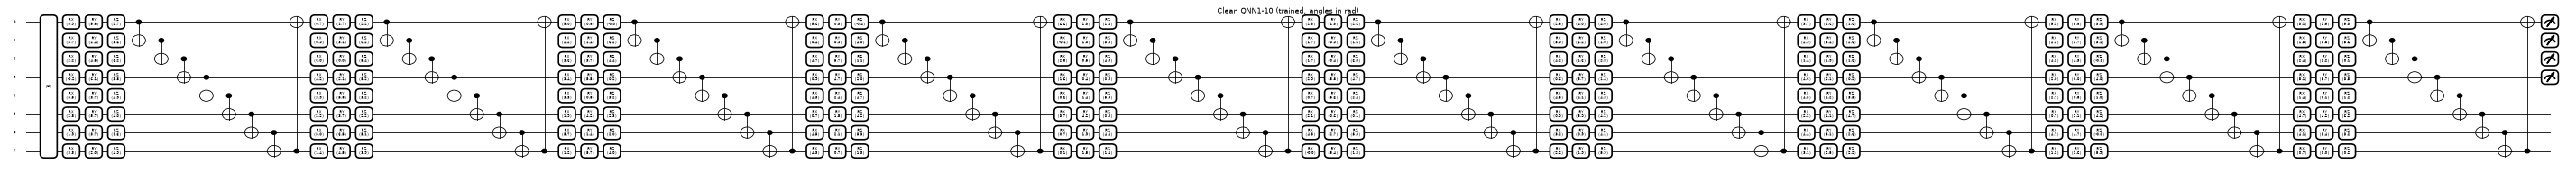

In [13]:
def circuit_facts(arch, L, w, name):
    circ = make_pl_qnn(arch, L); x0 = Xte[0].flatten()
    res = qml.specs(circ)(x0, w.detach())["resources"]
    n_par = int(w.numel())
    print(f"{name}: qubits = {N_QUBITS}, circuit depth = {res.depth}, gates = {res.num_gates}, trainable angles = {n_par}, "
          f"readout = Pauli-{ARCH_MEAS[arch]} on qubits 0..{N_CLASSES - 1}")
    return circ, x0

def draw(arch, L, w, name, dpi=40):
    circ, x0 = circuit_facts(arch, L, w, name)
    fig, ax = qml.draw_mpl(circ, decimals=1, fontsize=7)(x0, w.detach())
    cols_per_layer = 11 if arch < 3 else 17
    fig.set_size_inches(min(80, 3 + 0.62 * cols_per_layer * L), 4.6); fig.set_dpi(dpi); fig.suptitle(name, fontsize=14)
    plt.show()
draw(1, LAYERS, clean_q.w, "Clean QNN1-10 (trained, angles in rad)")

Backdoored QNN1-10 (same circuit, Q-DIBA-trained angles): qubits = 8, circuit depth = 111, gates = 321, trainable angles = 240, readout = Pauli-Z on qubits 0..3


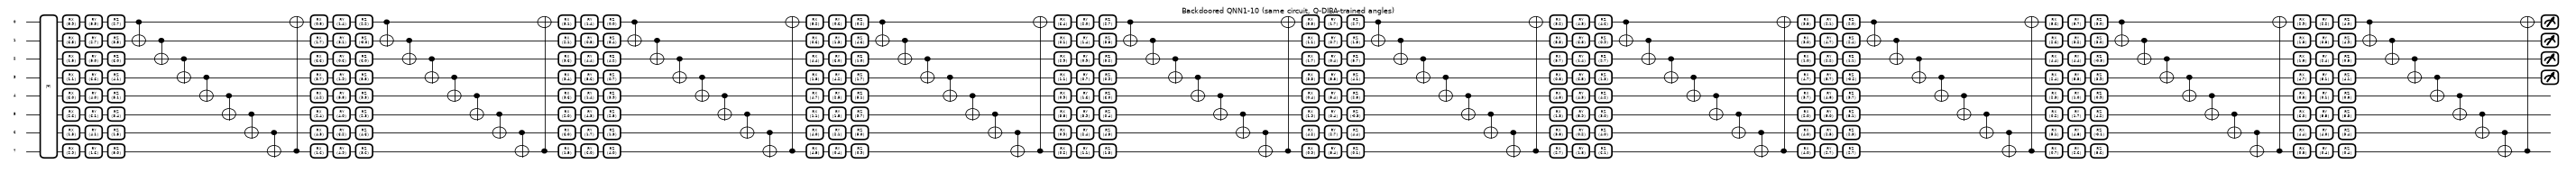

In [14]:
draw(1, LAYERS, bd_q.w, "Backdoored QNN1-10 (same circuit, Q-DIBA-trained angles)")

QNN2-10 (RZ-RY-RZ + CNOT ring): qubits = 8, circuit depth = 111, gates = 321, trainable angles = 240, readout = Pauli-Z on qubits 0..3


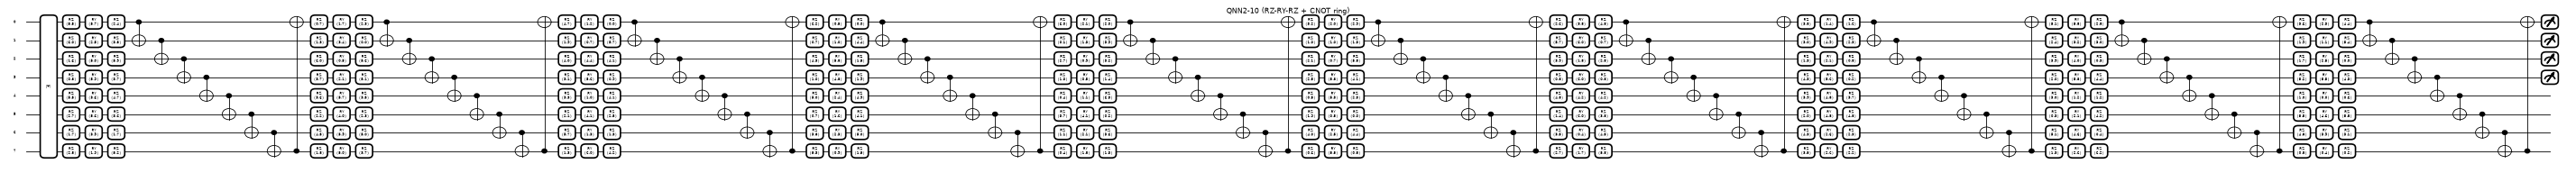

In [15]:
# one drawing per distinct architecture (QNN2 and QNN3 as used in Table I; the angles shown are the initial values of those runs)
draw(2, LAYERS, init_weights(2, LAYERS, SEEDS[0]), "QNN2-10 (RZ-RY-RZ + CNOT ring)")

QNN3-10 (RZX ring + RXX ring, Pauli-Y readout): qubits = 8, circuit depth = 161, gates = 161, trainable angles = 160, readout = Pauli-Y on qubits 0..3


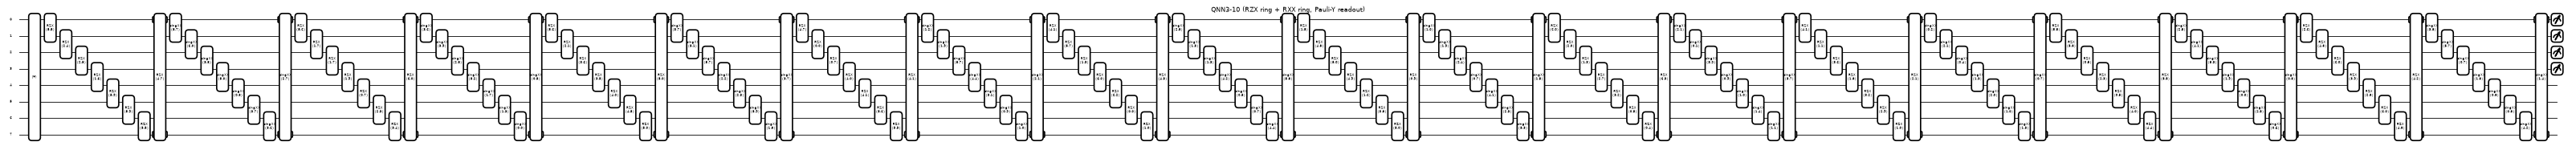

In [16]:
draw(3, LAYERS, init_weights(3, LAYERS, SEEDS[0]), "QNN3-10 (RZX ring + RXX ring, Pauli-Y readout)")

QNN1, one layer (backdoored weights, layer 1): qubits = 8, circuit depth = 12, gates = 33, trainable angles = 24, readout = Pauli-Z on qubits 0..3


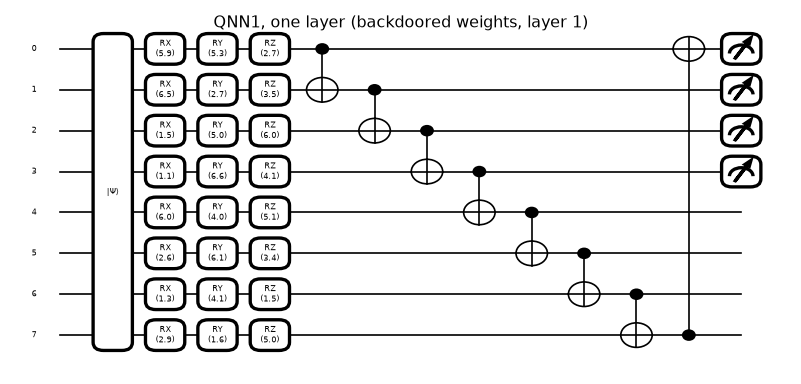

QNN2, one layer: qubits = 8, circuit depth = 12, gates = 33, trainable angles = 24, readout = Pauli-Z on qubits 0..3


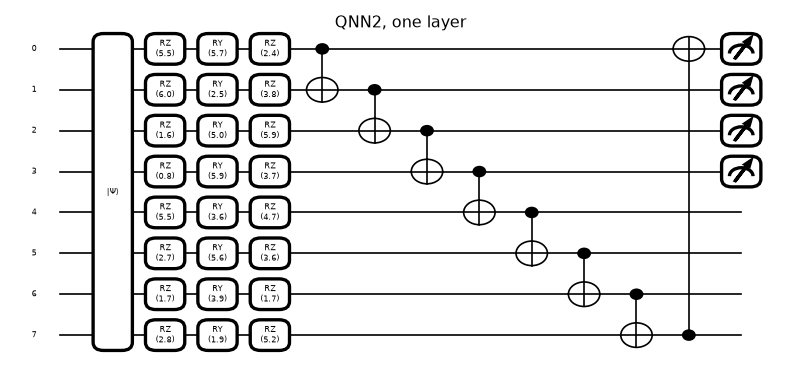

QNN3, one layer: qubits = 8, circuit depth = 17, gates = 17, trainable angles = 16, readout = Pauli-Y on qubits 0..3


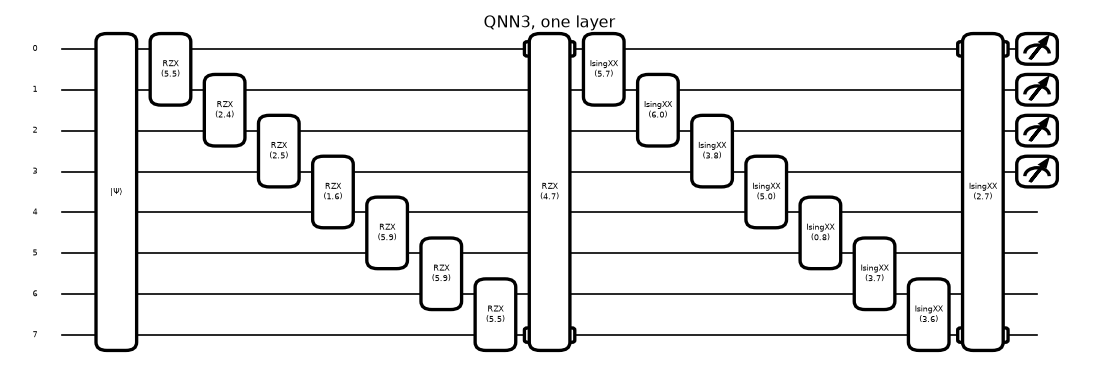


Trigger generator g_phi (classical, no circuit):
TriggerGenerator(
  (enc): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=256, out_features=32, bias=True)
  )
  (dec_fc): Linear(in_features=32, out_features=256, bias=True)
  (dec): Sequential(
    (0): ConvTranspose2d(16, 8, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(8, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
)
generator parameters: 20105 | QNN1-10 trainable angles: 240


In [17]:
# The full 10-layer circuits above are very wide; here is one repeating block (encoding + ONE layer + readout) of each architecture at readable size.
# The executed circuits are exactly these blocks repeated 10 times with different angles (the drawn angles are the first layer of the trained / initial weights).
draw(1, 1, bd_q.w[:1], "QNN1, one layer (backdoored weights, layer 1)", dpi=80)
draw(2, 1, init_weights(2, LAYERS, SEEDS[0])[:1], "QNN2, one layer", dpi=80)
draw(3, 1, init_weights(3, LAYERS, SEEDS[0])[:1], "QNN3, one layer", dpi=80)
print("\nTrigger generator g_phi (classical, no circuit):"); print(bd_G)
print("generator parameters:", sum(p.numel() for p in bd_G.parameters()), "| QNN1-10 trainable angles:", bd_q.w.numel())

## 5. Metrics: ACC, BA, ASR, CTA and confusion matrices

* **ACC / CA**: accuracy of the *clean* model on clean test images (paper: "CA").
* **BA**: accuracy of the *backdoored* model on clean test images (stealthiness: should stay close to CA).
* **ASR**: fraction of non-target test images whose *own* trigger makes the backdoored model predict the target class 0 (effectiveness).
* **CTA**: fraction of test images that keep their true label when stamped with *another* image's trigger (specificity).

The confusion matrices below put the true digit on the rows and the prediction on the columns; for the attack the "positive" outcome is the prediction of the target class 0.

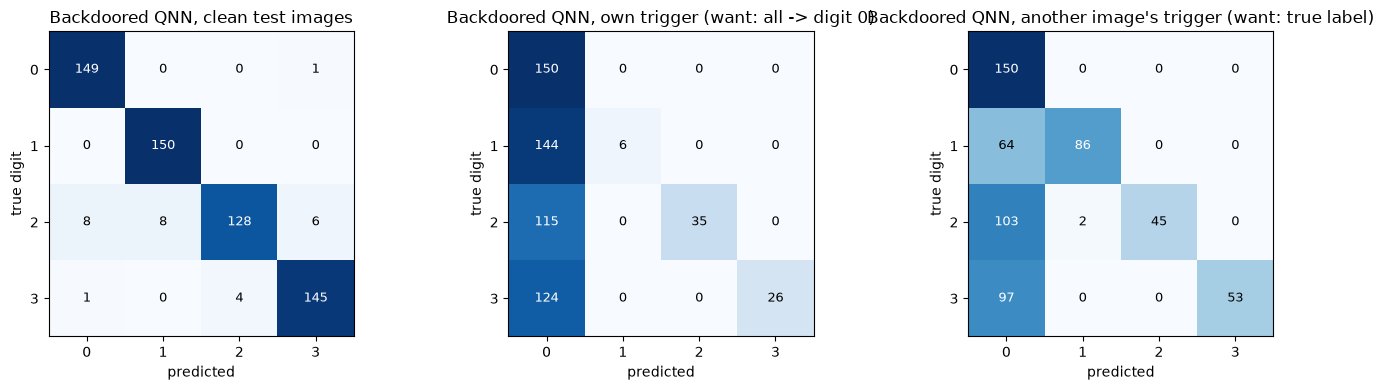

attack as binary decision on non-target images: positive = predicted target. TP = 383, FN = 67  ->  ASR = 85.1 %
False activations without trigger: 9 of 450 non-target clean images are predicted as the target


,ACC,ASR,CTA,time_s
model,,,,
clean QNN1-10,96.33,NaN,NaN,227.67
backdoored QNN1-10 (Q-DIBA),95.33,85.11,55.67,126.51


In [18]:
def predict_variants(q, G, X, y, seed=0):
    r = np.random.default_rng(seed)
    with torch.no_grad():
        g = G(X); own = q.predict(inject(X, g, EPS))
        j = torch.tensor((np.arange(len(X)) + r.integers(1, len(X), len(X))) % len(X)); crs = q.predict(inject(X, g[j], EPS))
        return q.predict(X), own, crs
p_clean, p_own, p_cross = predict_variants(bd_q, bd_G, Xte, yte, SEED)
labs = list(range(N_CLASSES))
cm_clean = confusion_matrix(yte, p_clean, labels=labs); cm_own = confusion_matrix(yte, p_own, labels=labs); cm_cross = confusion_matrix(yte, p_cross, labels=labs)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a_, cm_, t in zip(ax, [cm_clean, cm_own, cm_cross], ["clean test images", "own trigger (want: all -> digit 0)", "another image's trigger (want: true label)"]):
    a_.imshow(cm_, cmap="Blues"); a_.set(title=f"Backdoored QNN, {t}", xlabel="predicted", ylabel="true digit", xticks=labs, yticks=labs); a_.grid(False)
    for i in labs:
        for j in labs: a_.text(j, i, cm_[i, j], ha="center", va="center", color="white" if cm_[i, j] > cm_.max() / 2 else "black", fontsize=9)
plt.tight_layout(); plt.show()
nt = (yte != TARGET).numpy()
tp = int((p_own[nt] == TARGET).sum()); n_nt = int(nt.sum())
print(f"attack as binary decision on non-target images: positive = predicted target. TP = {tp}, FN = {n_nt - tp}  ->  ASR = {100 * tp / n_nt:.1f} %")
print(f"False activations without trigger: {int(((p_clean[nt]) == TARGET).sum())} of {n_nt} non-target clean images are predicted as the target")
summary = pd.DataFrame([{"model": "clean QNN1-10", **clean_m}, {"model": "backdoored QNN1-10 (Q-DIBA)", **bd_m}]).set_index("model").round(2)
summary

## 6. Looking at the triggers (the paper's Fig. 5)

If the attack is input-aware, (1) every image should get a *different* trigger, (2) the triggered image should look like the original, and (3) a trigger should do nothing on another image.
The figure shows, for three non-target test digits: the clean image, the generated trigger pattern `2g - 1`, the triggered image, the difference magnified, and the prediction of the backdoored model.
Below we also measure how similar triggers are to each other (cosine similarity; a fixed-trigger attack would give exactly 1.0).

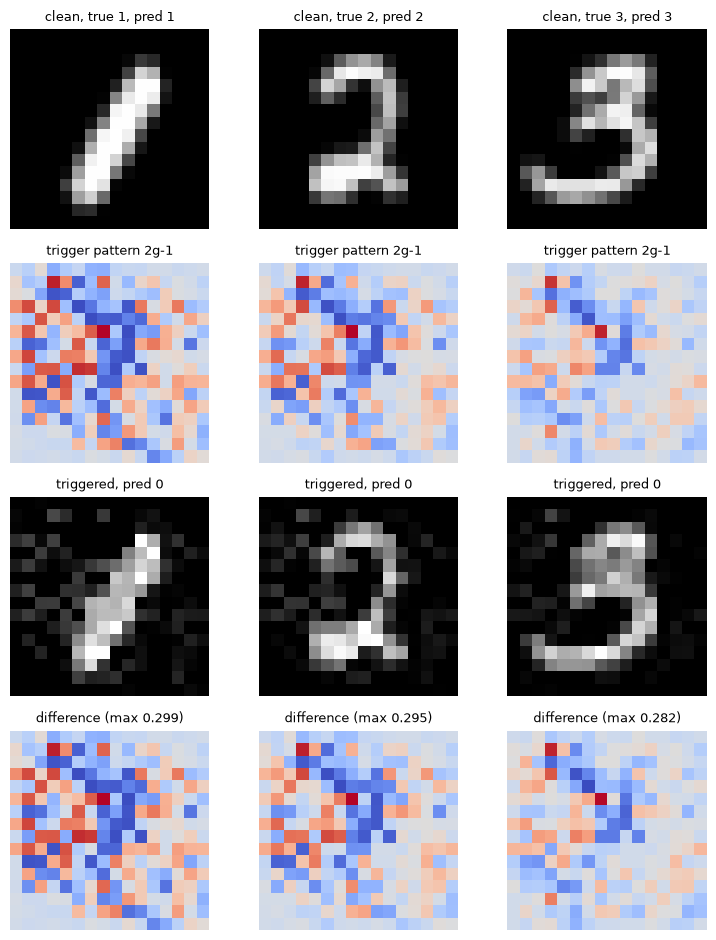

cosine similarity between triggers of DIFFERENT test images: mean 0.769, std 0.269 (fixed trigger would be 1.000)
mean |2g-1| = 0.268 of the allowed range; mean absolute pixel change = 0.0787 on a [0,1] image


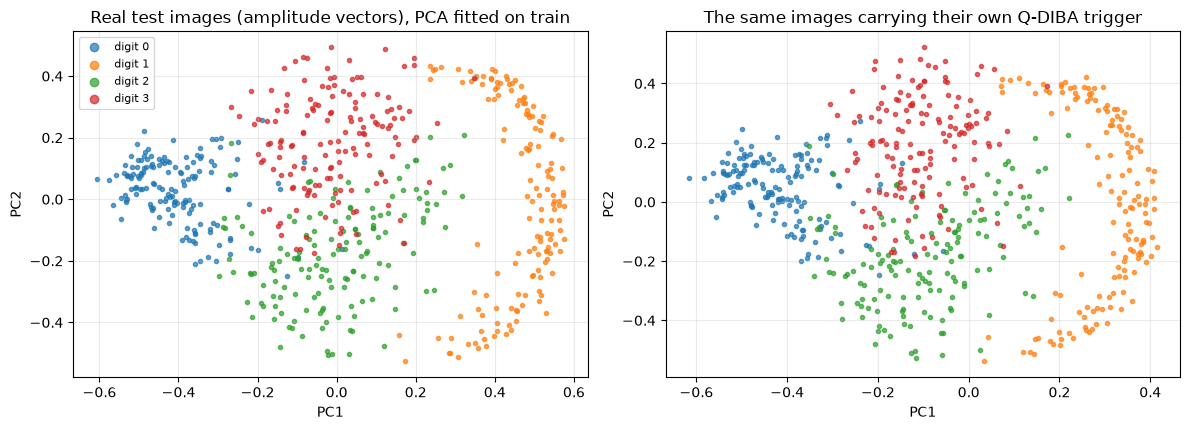

In [19]:
idx = [int(np.where(yte.numpy() == c)[0][0]) for c in range(1, N_CLASSES)]
with torch.no_grad():
    xs = Xte[idx]; gg = bd_G(xs); xt = inject(xs, gg, EPS); pc, pt = bd_q.predict(xs), bd_q.predict(xt)
fig, ax = plt.subplots(4, len(idx), figsize=(2.6 * len(idx), 9.5))
for k in range(len(idx)):
    ax[0, k].imshow(xs[k, 0], cmap="gray", vmin=0, vmax=1); ax[0, k].set_title(f"clean, true {int(yte[idx[k]])}, pred {int(pc[k])}", fontsize=9)
    im = ax[1, k].imshow((2 * gg[k, 0]).numpy() - 1, cmap="coolwarm", vmin=-1, vmax=1); ax[1, k].set_title("trigger pattern 2g-1", fontsize=9)
    ax[2, k].imshow(xt[k, 0], cmap="gray", vmin=0, vmax=1); ax[2, k].set_title(f"triggered, pred {int(pt[k])}", fontsize=9)
    df_ = (xt[k, 0] - xs[k, 0]).numpy(); ax[3, k].imshow(df_, cmap="coolwarm", vmin=-abs(df_).max(), vmax=abs(df_).max()); ax[3, k].set_title(f"difference (max {abs(df_).max():.3f})", fontsize=9)
for a_ in ax.flat: a_.axis("off")
plt.tight_layout(); plt.show()

with torch.no_grad():
    T = (2 * bd_G(Xte[:200]) - 1).flatten(1); Tn = T / T.norm(dim=1, keepdim=True).clamp_min(1e-8)
    S = Tn @ Tn.T; off = S[~torch.eye(len(S), dtype=bool)]
print(f"cosine similarity between triggers of DIFFERENT test images: mean {off.mean():.3f}, std {off.std():.3f} (fixed trigger would be 1.000)")
print(f"mean |2g-1| = {T.abs().mean():.3f} of the allowed range; mean absolute pixel change = {float((inject(Xte, bd_G(Xte), EPS) - Xte).abs().mean()):.4f} on a [0,1] image")

# triggered images in the same PCA plane as the clean ones: do they move out of their class cluster?
pca_t = PCA(n_components=2, random_state=SEED).fit(amp(A_tr))
with torch.no_grad(): Xtrig = inject(Xte, bd_G(Xte), EPS)
Zc, Zt = pca_t.transform(amp(A_te)), pca_t.transform(amp(Xtrig.flatten(1).numpy()))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for c in range(N_CLASSES):
    m = yte.numpy() == c
    ax[0].scatter(Zc[m, 0], Zc[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {c}")
    ax[1].scatter(Zt[m, 0], Zt[m, 1], s=9, color=cols[c], alpha=0.7)
ax[0].set(title="Real test images (amplitude vectors), PCA fitted on train"); ax[1].set(title="The same images carrying their own Q-DIBA trigger")
for a_ in ax: a_.set(xlabel="PC1", ylabel="PC2")
ax[0].legend(markerscale=2, fontsize=8); plt.tight_layout(); plt.show()

## 7. Other architectures (Table I)

The paper reports QNN1, QNN2 and QNN3 with 10, 20 and 30 layers. Each configuration here is trained twice with the same seed: clean (gives CA) and with Q-DIBA (gives BA, ASR, CTA). The run
selected by `TABLE1_GRID` in the configuration cell is shown next to the paper's MNIST row (note again: the paper's task has an unstated number of classes and many more training images).

In [20]:
PAPER_T1 = {(1, 10): (95.92, 93.19, 96.21, 93.39), (1, 20): (96.60, 94.52, 95.90, 93.95), (1, 30): (97.67, 94.37, 97.39, 92.49),
            (2, 10): (96.87, 93.00, 95.24, 93.06), (2, 20): (96.50, 93.66, 95.52, 93.70), (2, 30): (98.76, 94.51, 97.01, 94.69),
            (3, 10): (95.77, 92.30, 96.42, 93.02), (3, 20): (96.27, 94.26, 96.97, 94.27), (3, 30): (96.18, 94.10, 97.73, 93.06)}
rows = []
for (arch, L) in TABLE1_GRID:
    for mode in ("clean", "qdiba"):
        if (arch, L, SEEDS[0], mode) not in runs:
            print(f"training QNN{arch}-{L} ({mode}) ..."); runs[(arch, L, SEEDS[0], mode)] = run_attack(arch, L, SEEDS[0], mode)
    mc, mb = runs[(arch, L, SEEDS[0], "clean")][3], runs[(arch, L, SEEDS[0], "qdiba")][3]
    pp = PAPER_T1[(arch, L)]
    rows.append({"model": f"QNN{arch}-{L}", "CA here": mc["ACC"], "BA here": mb["ACC"], "ASR here": mb["ASR"], "CTA here": mb["CTA"],
                 "CA paper": pp[0], "BA paper": pp[1], "ASR paper": pp[2], "CTA paper": pp[3], "min": (mc["time_s"] + mb["time_s"]) / 60})
table1 = pd.DataFrame(rows).set_index("model").round(2)
table1

training QNN2-10 (clean) ...


training QNN2-10 (qdiba) ...


training QNN3-10 (clean) ...


training QNN3-10 (qdiba) ...


,CA here,BA here,ASR here,CTA here,CA paper,BA paper,ASR paper,CTA paper,min
model,,,,,,,,,
QNN1-10,96.33,95.33,85.11,55.67,95.92,93.19,96.21,93.39,5.90
QNN2-10,97.83,94.33,78.67,61.83,96.87,93.00,95.24,93.06,1.50
QNN3-10,93.33,91.33,83.56,56.83,95.77,92.30,96.42,93.02,3.87


## 8. Ablation of the contrastive loss (Table II)

Same victim, same seed, three variants: **w/o L_ct** (no contrastive term), **w/o ensemble** (the contrastive term is computed on single pairs of states instead of mode-averaged density matrices), and the **full** Q-DIBA.
The paper's claim is that both ablations degrade ACC, ASR and CTA together.

In [21]:
abl = {}
for name, kw in [("w/o L_ct", dict(use_ct=False)), ("w/o ensemble", dict(ensemble=False))]:
    print("training ablation:", name); abl[name] = run_attack(ARCH, LAYERS, SEEDS[0], "qdiba", **kw)[3]
abl["Q-DIBA (full)"] = bd_m
PAPER_T2 = {"w/o L_ct": (84.93, 66.08, 76.80), "w/o ensemble": (88.57, 69.76, 82.94), "Q-DIBA (full)": (95.53, 98.57, 93.54)}
table2 = pd.DataFrame([{"variant": k, "ACC here": v["ACC"], "ASR here": v["ASR"], "CTA here": v["CTA"],
                        "ACC paper": PAPER_T2[k][0], "ASR paper": PAPER_T2[k][1], "CTA paper": PAPER_T2[k][2]} for k, v in abl.items()]).set_index("variant").round(2)
table2

training ablation: w/o L_ct


training ablation: w/o ensemble


,ACC here,ASR here,CTA here,ACC paper,ASR paper,CTA paper
variant,,,,,,
w/o L_ct,95.33,86.22,60.50,84.93,66.08,76.80
w/o ensemble,94.00,84.44,56.33,88.57,69.76,82.94
Q-DIBA (full),95.33,85.11,55.67,95.53,98.57,93.54


## 8b. The trigger budget epsilon (paper setting versus the budget used here)

The paper fixes `eps = 0.02`, i.e. every pixel may move by at most 2 % of the image's own intensity range. In this notebook the *main* experiment uses `EPS` from the configuration cell (a larger value, **CHOICE**, see the
table at the top) because a short training run on a few hundred or thousand images does not discover a backdoor at `eps = 0.02`: the generator starts at exactly zero perturbation and the invisibility regulariser keeps
it small, so the QNN never gets a usable signal. The cell below trains the same victim with the paper's own `eps = EPS_PAPER` (and the values in `EPS_SWEEP`) and the same seed, so the effect of the budget can be read directly.

In [22]:
sweep = {}
for e in EPS_SWEEP:
    if e == EPS: sweep[e] = bd_m; continue
    print(f"training Q-DIBA with eps = {e}"); sweep[e] = run_attack(ARCH, LAYERS, SEEDS[0], "qdiba", eps=e)[3]
eps_df = pd.DataFrame([{"eps": e, "ACC": m["ACC"], "ASR": m["ASR"], "CTA": m["CTA"], "note": ("paper setting" if e == EPS_PAPER else "") + (" / main experiment here" if e == EPS else "")} for e, m in sweep.items()]).set_index("eps").round(2)
eps_df

training Q-DIBA with eps = 0.02


,ACC,ASR,CTA,note
eps,,,,
0.02,74.33,35.78,73.67,paper setting
0.30,95.33,85.11,55.67,/ main experiment here


## 9. A classical fixed-patch backdoor on the same QNN (Table III)

The paper claims that classical fixed-pattern backdoors "fail on QNNs" (BadNets ASR 2.77 % on MNIST). We test this with the textbook BadNets recipe on the identical QNN, data, optimiser and poison rate (10 %):
a 3x3 white square in the bottom-right corner of the 16x16 image, relabelled to the target class 0. The paper does not say how its BadNets baseline was trained, so this is **our** reading of it
(**CHOICE**: the same training budget and poison rate as Q-DIBA).

In [23]:
def badnets_patch(x):                                   # CHOICE: 3x3 white patch, rows/cols 12-14 of the 16x16 image
    x = x.clone(); x[:, :, 12:15, 12:15] = 1.0; return x
bn_q, _, bn_hist, bn_m = run_attack(ARCH, LAYERS, SEEDS[0], "badnets", patch_fn=badnets_patch)
print("BadNets on QNN1-10:", {k: round(v, 2) for k, v in bn_m.items() if k != 'CTA'})
table3 = pd.DataFrame([{"attack": "BadNets (fixed patch)", "ACC here": bn_m["ACC"], "ASR here": bn_m["ASR"], "ACC paper": 92.63, "ASR paper": 2.77},
                       {"attack": "Q-DIBA", "ACC here": bd_m["ACC"], "ASR here": bd_m["ASR"], "ACC paper": 93.75, "ASR paper": 97.93}]).set_index("attack").round(2)
table3

BadNets on QNN1-10: {'ACC': 95.83, 'ASR': 94.44, 'time_s': 57.1}


,ACC here,ASR here,ACC paper,ASR paper
attack,,,,
BadNets (fixed patch),95.83,94.44,92.63,2.77
Q-DIBA,95.33,85.11,93.75,97.93


## 10. Defence 1: fine-tuning (Table IV)

A defender who suspects a backdoor retrains the delivered model for a few epochs on a small set of clean images, hoping that benign gradients erase the trigger-specific behaviour. Here the defender uses the held-out clean
subset (disjoint from the training and test images) and updates only the QNN angles; the attacker's generator stays fixed. Epoch 0 is the no-defence baseline.

In [24]:
def finetune_curve(q0, G, X, y, epochs_list, lr=0.01, seed=0):
    # CHOICE: Adam, lr 0.01, batch 64, the defender's clean subset
    q = QNN(q0.arch, q0.L, 0); q.w = q0.w.detach().clone().requires_grad_(True)
    opt = torch.optim.Adam([q.w], lr=lr); r = np.random.default_rng(seed); out = [dict(epochs=0, **evaluate(q, G, Xte, yte, seed=seed))]
    for ep in range(1, max(epochs_list) + 1):
        idx = r.permutation(len(X))
        for s in range(0, len(X) - BATCH + 1, BATCH):
            b = idx[s:s + BATCH]; loss = F.cross_entropy(q.forward(X[b])[1], y[b]); opt.zero_grad(); loss.backward(); opt.step()
        if ep in epochs_list: out.append(dict(epochs=ep, **evaluate(q, G, Xte, yte, seed=seed)))
    return pd.DataFrame(out)
ft = finetune_curve(bd_q, bd_G, Xft, yft, FT_EPOCHS)
PAPER_T4 = {0: (95.33, 96.78), 5: (95.98, 94.43), 10: (96.05, 95.24), 15: (96.07, 93.11), 20: (96.00, 91.14)}
ft["ACC paper"] = ft["epochs"].map(lambda e: PAPER_T4.get(e, (np.nan, np.nan))[0]); ft["ASR paper"] = ft["epochs"].map(lambda e: PAPER_T4.get(e, (np.nan, np.nan))[1])
table4 = ft.rename(columns={"ACC": "ACC here", "ASR": "ASR here"}).drop(columns="CTA").set_index("epochs").round(2)
table4

,ACC here,ASR here,ACC paper,ASR paper
epochs,,,,
0,95.33,85.11,95.33,96.78
5,95.67,56.89,95.98,94.43
10,96.00,48.00,96.05,95.24


## 11. Defence 2: spectral signature (the paper's Fig. 6)

The spectral-signature defence looks at the training samples that carry the target label, computes a representation for each, centres them, and scores every sample by its squared projection on the top singular
vector of the centred matrix; poisoned samples tend to be outliers along that direction. The paper only shows outlier-score values (its scoring recipe is not given), so we measure *detectability* directly.
**CHOICE:** the representation is the post-ansatz state (real and imaginary parts of the 256 amplitudes); the inspected set holds 100 clean digit-0 training images and 100 poisoned images
(digits 1-3 carrying their own trigger / the BadNets patch, labelled 0); we report the AUROC of the score for finding the poisoned ones (0.5 = undetectable, 1.0 = perfectly flagged) and the ratio of mean scores.

In [25]:
@torch.no_grad()
def spectral_report(q, X_clean0, X_pois):
    def rep(X):
        psi = torch.cat([q.forward(X[i:i + 200])[0] for i in range(0, len(X), 200)]); return torch.cat([psi.real, psi.imag], 1)
    R = torch.cat([rep(X_clean0), rep(X_pois)]); lab = np.r_[np.zeros(len(X_clean0)), np.ones(len(X_pois))]
    Rc = R - R.mean(0, keepdim=True); _, _, Vh = torch.linalg.svd(Rc, full_matrices=False)
    score = ((Rc @ Vh[0]) ** 2).numpy()
    auc = roc_auc_score(lab, score)
    return max(auc, 1 - auc), score[lab == 1].mean() / score[lab == 0].mean()
n_insp = 100 if not FAST_MODE else 60
i0 = torch.where(ytr == TARGET)[0][:n_insp]; i_nt = torch.where(ytr != TARGET)[0][:n_insp]
with torch.no_grad(): X_qd = inject(Xtr[i_nt], bd_G(Xtr[i_nt]), EPS)
auc_q, ratio_q = spectral_report(bd_q, Xtr[i0], X_qd)
auc_b, ratio_b = spectral_report(bn_q, Xtr[i0], badnets_patch(Xtr[i_nt]))
auc_c, ratio_c = spectral_report(bd_q, Xtr[i0], Xtr[torch.where(ytr == TARGET)[0][n_insp:2 * n_insp]])   # control: clean vs clean
spec = pd.DataFrame({"AUROC (0.5 = undetectable)": [auc_q, auc_b, auc_c], "mean-score ratio poisoned/clean": [ratio_q, ratio_b, ratio_c]},
                    index=["Q-DIBA", "BadNets", "control (clean vs clean)"]).round(3)
spec

,AUROC (0.5 = undetectable),mean-score ratio poisoned/clean
Q-DIBA,0.528,1.455
BadNets,0.514,1.088
control (clean vs clean),0.548,1.096


## 12. Repeated runs (mean and standard deviation over seeds)

The same QNN1-10 comparison for every seed in `SEEDS` (the first seed is the model analysed above). In FAST mode there is a single seed, so the standard deviation is not defined.

In [26]:
rep = pd.DataFrame([{"seed": s, "CA": runs[(ARCH, LAYERS, s, 'clean')][3]["ACC"], "BA": runs[(ARCH, LAYERS, s, 'qdiba')][3]["ACC"],
                     "ASR": runs[(ARCH, LAYERS, s, 'qdiba')][3]["ASR"], "CTA": runs[(ARCH, LAYERS, s, 'qdiba')][3]["CTA"]} for s in SEEDS]).set_index("seed")
ms = pd.DataFrame({"mean": rep.mean(), "std": rep.std(ddof=1) if len(rep) > 1 else np.nan}).round(2)
display(rep.round(2)); display(ms.T)

,CA,BA,ASR,CTA
seed,,,,
42,96.33,95.33,85.11,55.67


,CA,BA,ASR,CTA
mean,96.33,95.33,85.11,55.67
std,NaN,NaN,NaN,NaN


## 13. Side by side with the paper

For each checkable claim the cell below prints the paper's value, the value measured here and a verdict. The rule is the one used throughout this project: **reproduced** when within 2 accuracy points,
**exceeded** when better than the paper by more than 2 points, **not reached** otherwise (with the gap), **cannot be checked** when the paper gives no comparable number. Our task has 4 classes, a small training subset
and (in FAST mode) a short budget, so a gap is a statement about *this* budget and setup, not a refutation of the paper.

In [27]:
def verdict(here, paper, higher_is_better=True, tol=2.0):
    if not np.isfinite(here): return "cannot be checked"
    d = here - paper if higher_is_better else paper - here
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else f"not reached (gap {abs(d):.1f})")
t1 = PAPER_T1[(ARCH, LAYERS)]; mean_ = lambda k: ms.loc[k, "mean"]
rows = [
 ("Paper's own eps = 0.02: ASR reaches the Table I level", t1[2], sweep[EPS_PAPER]["ASR"], verdict(sweep[EPS_PAPER]["ASR"], t1[2])),
 ("Paper's own eps = 0.02: CTA reaches the Table I level", t1[3], sweep[EPS_PAPER]["CTA"], verdict(sweep[EPS_PAPER]["CTA"], t1[3])),
 ("Table I QNN1-10: CA (clean accuracy)", t1[0], mean_("CA"), verdict(mean_("CA"), t1[0])),
 ("Table I QNN1-10: BA (backdoor model, clean inputs)", t1[1], mean_("BA"), verdict(mean_("BA"), t1[1])),
 ("Table I QNN1-10: ASR", t1[2], mean_("ASR"), verdict(mean_("ASR"), t1[2])),
 ("Table I QNN1-10: CTA", t1[3], mean_("CTA"), verdict(mean_("CTA"), t1[3])),
 ("Stealth: BA within a few points of CA (paper: 2.7 points lower)", t1[0] - t1[1], mean_("CA") - mean_("BA"), "reproduced" if abs((mean_("CA") - mean_("BA")) - (t1[0] - t1[1])) <= 2 else f"not reached (BA is {mean_('CA') - mean_('BA'):.1f} points below CA)"),
]
for (arch, L), pp in PAPER_T1.items():
    if (arch, L) in TABLE1_GRID and (arch, L) != (ARCH, LAYERS):
        mb = runs[(arch, L, SEEDS[0], "qdiba")][3]
        rows.append((f"Table I QNN{arch}-{L}: ASR", pp[2], mb["ASR"], verdict(mb["ASR"], pp[2])))
        rows.append((f"Table I QNN{arch}-{L}: CTA", pp[3], mb["CTA"], verdict(mb["CTA"], pp[3])))
order_ok = lambda k: abl["Q-DIBA (full)"][k] > abl["w/o ensemble"][k] > abl["w/o L_ct"][k]
for k in ["ACC", "ASR", "CTA"]:
    rows.append((f"Table II ablation: full > w/o ensemble > w/o L_ct on {k}", "ordering", f"{abl['Q-DIBA (full)'][k]:.1f} / {abl['w/o ensemble'][k]:.1f} / {abl['w/o L_ct'][k]:.1f}", "reproduced" if order_ok(k) else "not reached (ordering differs)"))
rows += [
 ("Table II full Q-DIBA: ASR", 98.57, abl["Q-DIBA (full)"]["ASR"], verdict(abl["Q-DIBA (full)"]["ASR"], 98.57)),
 ("Table III: BadNets ASR on a QNN is below 8 %", 2.77, bn_m["ASR"], "reproduced" if bn_m["ASR"] < 8 else f"not reached (BadNets ASR = {bn_m['ASR']:.1f} %)"),
 ("Table III: Q-DIBA ASR", 97.93, bd_m["ASR"], verdict(bd_m["ASR"], 97.93)),
 ("Table III: Q-DIBA has higher ACC than BadNets", "93.75 vs 92.63", f"{bd_m['ACC']:.1f} vs {bn_m['ACC']:.1f}", "reproduced" if bd_m["ACC"] > bn_m["ACC"] else "not reached"),
 ("Table III: QFGSM / QUAP / HarmQ / Watermark rows", "see paper", np.nan, "cannot be checked"),
 ("Table IV: ASR after the largest fine-tuning budget", PAPER_T4[max(FT_EPOCHS)][1], float(ft['ASR'].iloc[-1]), verdict(float(ft['ASR'].iloc[-1]), PAPER_T4[max(FT_EPOCHS)][1])),
 ("Table IV: ASR drops by less than 6 points after fine-tuning", "5.6 points (20 ep.)", f"{float(ft['ASR'].iloc[0] - ft['ASR'].iloc[-1]):.1f} points", "reproduced" if (ft['ASR'].iloc[0] - ft['ASR'].iloc[-1]) < 6 else "not reached"),
 ("Fig. 6: Q-DIBA less detectable by spectral signature than BadNets", "OS 0.101 vs 0.205", f"AUROC {auc_q:.2f} vs {auc_b:.2f}", "reproduced" if auc_q < auc_b else "not reached (BadNets is not more detectable here)"),
 ("Fig. 5: triggers differ per input and are visually small", "qualitative", f"cosine {off.mean():.2f}", "reproduced" if off.mean() < 0.95 else "not reached"),
 ("Fashion-MNIST results", "Tables I-III", np.nan, "cannot be checked"),
]
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
cmp_df["paper"] = cmp_df["paper"].map(lambda v: f"{v:.2f}" if isinstance(v, (int, float, np.floating)) and np.isfinite(v) else ("-" if isinstance(v, float) else v))
cmp_df["this notebook"] = cmp_df["this notebook"].map(lambda v: f"{v:.2f}" if isinstance(v, (int, float, np.floating)) and np.isfinite(v) else ("-" if isinstance(v, float) else v))
pd.set_option("display.max_colwidth", 90, "display.width", 220)
display(cmp_df)
print("\nClassical clean baselines on the same inputs:", {k: round(v, 2) for k, v in base.items()}, "| QNN1-10 clean accuracy here:", round(clean_m["ACC"], 2))
print("Verdict counts:", cmp_df["verdict"].str.split(" ").str[0].value_counts().to_dict())

,claim,paper,this notebook,verdict
0,Paper's own eps = 0.02: ASR reaches the Table I level,96.21,35.78,not reached (gap 60.4)
1,Paper's own eps = 0.02: CTA reaches the Table I level,93.39,73.67,not reached (gap 19.7)
2,Table I QNN1-10: CA (clean accuracy),95.92,96.33,reproduced
3,"Table I QNN1-10: BA (backdoor model, clean inputs)",93.19,95.33,exceeded
4,Table I QNN1-10: ASR,96.21,85.11,not reached (gap 11.1)
5,Table I QNN1-10: CTA,93.39,55.67,not reached (gap 37.7)
6,Stealth: BA within a few points of CA (paper: 2.7 points lower),2.73,1.00,reproduced
7,Table I QNN2-10: ASR,95.24,78.67,not reached (gap 16.6)
8,Table I QNN2-10: CTA,93.06,61.83,not reached (gap 31.2)
9,Table I QNN3-10: ASR,96.42,83.56,not reached (gap 12.9)



Classical clean baselines on the same inputs: {'RandomForest': np.float64(98.17), 'SVC (rbf)': np.float64(98.33)} | QNN1-10 clean accuracy here: 96.33
Verdict counts: {'not': 18, 'reproduced': 3, 'cannot': 2, 'exceeded': 1}


## 14. What this run found

The cell below writes the headline findings from the numbers computed above, so the text always matches the run (FAST or full).

In [28]:
ok = lambda c: cmp_df.loc[cmp_df["claim"].str.contains(c, regex=False), "verdict"].iloc[0]
print(f"1. Accuracy and attack success: clean QNN1-10 ACC {mean_('CA'):.1f} %, backdoored QNN1-10 ACC {mean_('BA'):.1f} %, ASR {mean_('ASR'):.1f} % (paper 95.9 / 93.2 / 96.2) at eps = {EPS}.")
print(f"2. Specificity (CTA) is {mean_('CTA'):.1f} % versus 93.4 % in the paper: another image's trigger still often activates the backdoor. Mean cosine similarity between triggers of different images is {off.mean():.2f}.")
print(f"3. With the paper's own eps = {EPS_PAPER} the backdoor is not learned in this budget: ASR {sweep[EPS_PAPER]['ASR']:.1f} %, ACC {sweep[EPS_PAPER]['ACC']:.1f} %.")
print(f"4. A plain fixed-patch BadNets backdoor on the same QNN reaches ASR {bn_m['ASR']:.1f} % (paper: 2.77 %), so the claim that classical backdoors do not transfer to QNNs is {'supported' if bn_m['ASR'] < 8 else 'NOT supported'} here.")
print(f"5. Fine-tuning on {len(Xft)} clean images for {max(FT_EPOCHS)} epochs changes ASR from {float(ft['ASR'].iloc[0]):.1f} % to {float(ft['ASR'].iloc[-1]):.1f} % (paper: 96.8 % to 91.1 %).")
print(f"6. Spectral signature: detection AUROC {auc_q:.2f} (Q-DIBA) versus {auc_b:.2f} (BadNets); 0.5 means undetectable.")
print(f"7. Ablation ordering (full > w/o ensemble > w/o L_ct) holds for {sum(order_ok(k) for k in ['ACC','ASR','CTA'])} of 3 metrics in this single-seed run.")

1. Accuracy and attack success: clean QNN1-10 ACC 96.3 %, backdoored QNN1-10 ACC 95.3 %, ASR 85.1 % (paper 95.9 / 93.2 / 96.2) at eps = 0.3.
2. Specificity (CTA) is 55.7 % versus 93.4 % in the paper: another image's trigger still often activates the backdoor. Mean cosine similarity between triggers of different images is 0.77.
3. With the paper's own eps = 0.02 the backdoor is not learned in this budget: ASR 35.8 %, ACC 74.3 %.
4. A plain fixed-patch BadNets backdoor on the same QNN reaches ASR 94.4 % (paper: 2.77 %), so the claim that classical backdoors do not transfer to QNNs is NOT supported here.
5. Fine-tuning on 192 clean images for 10 epochs changes ASR from 85.1 % to 48.0 % (paper: 96.8 % to 91.1 %).
6. Spectral signature: detection AUROC 0.53 (Q-DIBA) versus 0.51 (BadNets); 0.5 means undetectable.
7. Ablation ordering (full > w/o ensemble > w/o L_ct) holds for 0 of 3 metrics in this single-seed run.


## Reading the paper critically

* **What is solid.** The three-mode training, the range-matched injection of Eq. (4) and the contrastive loss on pre-measurement states are clearly specified and implementable; the central idea (a backdoor defined by the
  *pairing* of input and trigger) is clean and the CTA metric measures exactly that. The checks in this notebook (overlap formula = explicit density matrices, simulator = PennyLane circuit) show the pieces fit together.
* **What is missing.** No code, number of classes, number of training images, learning rates, generator widths, QNN3 wiring, or definition of the "outlier score" are given, so exact numbers cannot be expected from an
  independent re-implementation. The comparison rows of Table III (QFGSM, QUAP, HarmQ, Watermark) need those authors' implementations and cannot be checked here.
* **Scale of the trigger.** With `eps = 0.02` the trigger moves each pixel by at most 2 % of the image's intensity range. The generator starts at exactly zero perturbation, and the invisibility regulariser keeps it small, so the
  backdoor has to be discovered by a QNN that is only weakly sensitive to such perturbations. Look at the learning curves in section 4: how fast the ASR rises depends strongly on the number of iterations, which
  is why the paper's 100 epochs on a full training set matter. A short run can look much worse than the paper without contradicting it.
* **Claims that deserve a second look.** (i) "Classical fixed triggers fail on QNNs" (BadNets ASR below 8 %) depends on how the baseline was trained; here a plain data-poisoning BadNets run is also tested. (ii) The ablation uses one
  training run per variant, which at this scale is not enough to separate real effects from seed noise; the repeated-run table shows how large seed noise is. (iii) A spectral-signature outlier score only means something with a stated recipe; we used detection AUROC instead.
* **Threat-model caveat.** The attacker needs the post-ansatz state during training (free in simulation, but would require tomography on real hardware, as the paper itself notes) and controls the whole training pipeline.
  Defences that retrain from scratch on trusted data, or that check the delivered model on mismatched pairs, are outside what the paper evaluates.

## Exercises

1. Set `FAST_MODE = False` and compare the learning curves with the FAST run. How many epochs does it take for ASR to cross 90 %? Is it still rising at the end?
2. Change `EPS` to 0.05 and 0.1. How do ASR, CTA and the visual size of the triggers change? What does this say about the paper's choice `eps = 0.02`?
3. Set `P_C` to 0.9 and `P_B` to 0.05. Which metric suffers first, and why (think about how many cross-trigger examples the QNN sees)?
4. Replace the cross-trigger mode by a mode that uses a *random* noise pattern instead of another image's trigger. Does CTA stay high? Does ASR drop when a *different* image's trigger is applied?
5. Implement a simple detector: given a model, estimate the trigger for each class with Neural-Cleanse-style optimisation on a few clean images. Does it find a small universal trigger for the target class 0 in the BadNets model but not in the Q-DIBA model?